# Task 1: Naive Bayes Classifier

## Introduction

- **Objective:** implement a Naive Bayes classifier from scratch with NumPy, apply it to sentiment analysis, and compare it with scikit-learn's implementation.
- **Dataset:** IMDB Movie Reviews (50,000 reviews labeled positive or negative).
- **Approach:** both models use the **same bag-of-words features** and the **same smoothing value**, so any difference comes from the classifier and not from preprocessing.

| Step | Description |
|:---|:---|
| 1 | Dataset and exploratory data analysis |
| 2 | Preprocessing and feature extraction |
| 3 | Naive Bayes from scratch and its metrics |
| 4 | scikit-learn Naive Bayes and its metrics |
| 5 | Comparison of the two implementations |
| 6 | Conclusion |

## Theory

*(To be added.)*

In [1]:
# Imports

import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)


# Reproducibility

np.random.seed(42)

print("Setup complete")

Setup complete


## 1. Dataset and Exploratory Data Analysis

- **IMDB Dataset of 50K Movie Reviews:** each row has a `review` (text) and a `sentiment` (`positive` or `negative`).
- The classes are balanced, so accuracy is a fair measure here, though we still report precision, recall and F1.
- The reviews contain HTML tags (e.g. `<br />`), which are removed in preprocessing.

**EDA covers**
- Shape, missing values and duplicate reviews
- Class distribution
- Review length per class
- Most frequent words per class (stopwords removed for display only)
- Sample reviews

Shape: (50000, 2)
Missing values:
 review       0
sentiment    0
dtype: int64
Duplicate reviews: 418


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive



Class distribution:
 sentiment
positive    25000
negative    25000
Name: count, dtype: int64


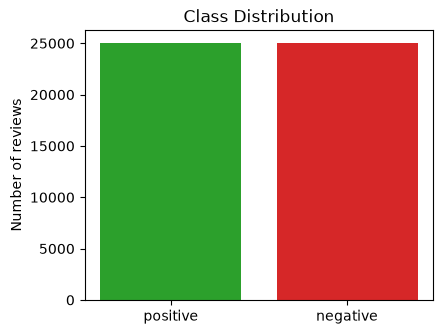


Review length statistics (words):


,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
negative,25000.0,229.5,164.9,4.0,128.0,174.0,278.0,1522.0
positive,25000.0,232.8,177.5,10.0,125.0,172.0,284.0,2470.0


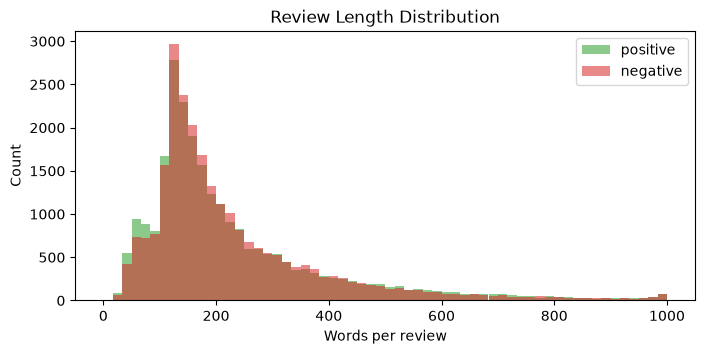

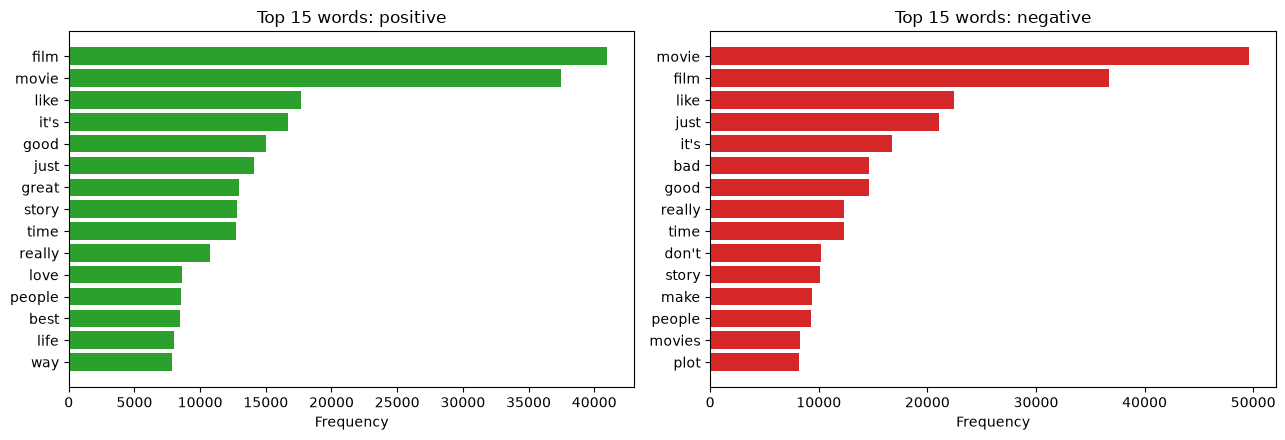


--- POSITIVE samples ---
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Tru ...

A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only "has got all the polari"  ...


--- NEGATIVE samples ---
Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fighting all the time.<br /><br />This movie is slower than a soap opera... and suddenly, Jake decides to become Rambo and kill the zombie.<br /><br />OK, first of all when you're going to ma ...

This show was an amazing, fres

In [2]:
# Load the dataset (set this to the location of your CSV file)

DATA_PATH = r"C:\Users\rithy\OneDrive\Desktop\marvel_level3\task1\IMDB Dataset.csv"
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
print("Missing values:\n", df.isnull().sum())
print("Duplicate reviews:", df.duplicated(subset="review").sum())
display(df.head())


# Class distribution

counts = df["sentiment"].value_counts()
print("\nClass distribution:\n", counts)

plt.figure(figsize=(4.5, 3.5))
plt.bar(counts.index, counts.values, color=["tab:green", "tab:red"])
plt.ylabel("Number of reviews")
plt.title("Class Distribution")
plt.show()


# Review length (number of words) per class

df["n_words"] = df["review"].str.split().str.len()
print("\nReview length statistics (words):")
display(df.groupby("sentiment")["n_words"].describe().round(1))

plt.figure(figsize=(8, 3.5))
for label, color in [("positive", "tab:green"), ("negative", "tab:red")]:
    plt.hist(df.loc[df["sentiment"] == label, "n_words"], bins=60, range=(0, 1000),
             alpha=0.55, label=label, color=color)
plt.xlabel("Words per review")
plt.ylabel("Count")
plt.title("Review Length Distribution")
plt.legend()
plt.show()


# Most frequent words per class (HTML removed, stopwords removed for display only)

def simple_tokens(text):
    text = re.sub(r"<[^>]+>", " ", text.lower())          # strip HTML tags
    return [w for w in re.findall(r"[a-z']{2,}", text) if w not in ENGLISH_STOP_WORDS]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (label, color) in zip(axes, [("positive", "tab:green"), ("negative", "tab:red")]):
    counter = Counter()
    for review in df.loc[df["sentiment"] == label, "review"]:
        counter.update(simple_tokens(review))
    words, freqs = zip(*counter.most_common(15))
    ax.barh(words[::-1], freqs[::-1], color=color)
    ax.set_title(f"Top 15 words: {label}")
    ax.set_xlabel("Frequency")
plt.tight_layout()
plt.show()


# Sample reviews

for label in ["positive", "negative"]:
    print(f"\n--- {label.upper()} samples ---")
    for text in df.loc[df["sentiment"] == label, "review"].head(2):
        print(text[:300], "...\n")

### 2. Preprocessing

| Step | What it does | Why |
|:---|:---|:---|
| **Remove duplicates** | Drops repeated reviews | Prevents the same review from appearing in both train and test |
| **Clean text** | Lowercases, removes HTML tags, and replaces everything except letters and apostrophes with spaces | Removes noise; apostrophes are kept so words like `don't` stay intact |
| **Encode labels** | `positive` = 1, `negative` = 0 | Models need numeric labels |
| **Stratified split** | 80% train, 20% test, preserving class proportions | Fair evaluation on unseen data |
| **Bag of words** | `CountVectorizer` with the top 10,000 words, **fitted on the training set only** | Turns text into word-count vectors; fitting on train only avoids data leakage |

- Stopwords are **not** removed, because words like `not` and `no` carry sentiment.
- The count matrix is stored as a **sparse matrix**, since most entries are zero. A dense 40,000 × 10,000 matrix would need several gigabytes.
- Both models use this same matrix.

In [4]:
# Remove duplicate reviews

before = len(df)
df = df.drop_duplicates(subset="review").reset_index(drop=True)
print(f"Removed {before - len(df)} duplicates | Remaining: {len(df)}")


# Clean the text

def clean_text(text):
    text = text.lower()
    text = re.sub(r"<[^>]+>", " ", text)                  # remove HTML tags
    text = re.sub(r"[^a-z']", " ", text)                  # keep only letters and apostrophes
    return re.sub(r"\s+", " ", text).strip()              # collapse extra spaces

df["clean_review"] = df["review"].apply(clean_text)

print("\nBefore:", df["review"][0][:200])
print("After: ", df["clean_review"][0][:200])


# Encode labels

df["label"] = (df["sentiment"] == "positive").astype(int)


# Stratified train/test split (80/20)

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["clean_review"], df["label"].values,
    test_size=0.2, stratify=df["label"].values, random_state=42
)

print("\nTrain size:", len(X_train_text), "| Test size:", len(X_test_text))
print("Positive fraction (train):", y_train.mean().round(4), "| (test):", y_test.mean().round(4))


# Bag of words (fit on the training set only)

vectorizer = CountVectorizer(max_features=10000, token_pattern=r"[a-z']{2,}")
X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)

vocab = vectorizer.get_feature_names_out()
print("\nTrain matrix:", X_train.shape, "| Test matrix:", X_test.shape)
print("Vocabulary size:", len(vocab))
print("Sparsity (share of zero entries):", round(1 - X_train.nnz / np.prod(X_train.shape), 4))

Removed 418 duplicates | Remaining: 49582

Before: One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me abo
After:  one of the other reviewers has mentioned that after watching just oz episode you'll be hooked they are right as this is exactly what happened with me the first thing that struck me about oz was its br

Train size: 39665 | Test size: 9917
Positive fraction (train): 0.5019 | (test): 0.5019

Train matrix: (39665, 10000) | Test matrix: (9917, 10000)
Vocabulary size: 10000
Sparsity (share of zero entries): 0.9875


### 3. Naive Bayes From Scratch

**Model:** Multinomial Naive Bayes, which suits word-count features.

| Method | What it does |
|:---|:---|
| `fit` | Computes the log class priors and, for each class, the Laplace-smoothed log probability of every word: $\log\dfrac{\text{count}(w, c) + \alpha}{\text{total words in } c + \alpha V}$ |
| `predict_log_proba` | For each review, adds the log prior to the sum of (word count × log likelihood), then normalizes to get log posteriors |
| `predict` | Picks the class with the highest score |

- Everything is computed in **log space** to avoid numerical underflow from multiplying thousands of small probabilities.
- The score for all reviews and classes is a single matrix multiplication, so there is no Python loop over words.
- NumPy does the computation; SciPy's sparse matrix is only used to hold the features.

**Metrics (also written from scratch)**

| Metric | Formula |
|:---|:---|
| Accuracy | $\dfrac{TP + TN}{TP + TN + FP + FN}$ |
| Precision | $\dfrac{TP}{TP + FP}$ |
| Recall | $\dfrac{TP}{TP + FN}$ |
| F1 score | $\dfrac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$ |

- The **positive class** is a positive review (label 1).

From-scratch metrics:
  Accuracy  : 0.8410
  Precision : 0.8562
  Recall    : 0.8210
  F1        : 0.8382


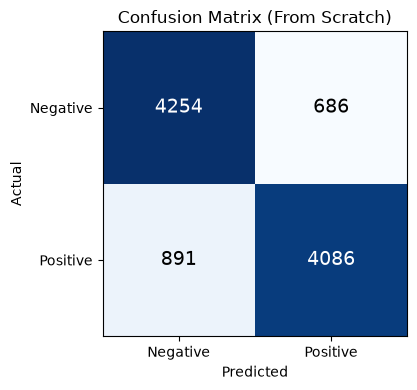


'this movie was absolutely wonderful and moving' -> positive (P(neg)=0.189, P(pos)=0.811)

'a boring, terrible waste of time' -> negative (P(neg)=0.998, P(pos)=0.002)


In [5]:
# Naive Bayes classifier from scratch

class MultinomialNaiveBayes:
    def __init__(self, alpha=1.0):
        self.alpha = alpha                                 # Laplace smoothing value

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        n_classes, n_features = len(self.classes_), X.shape[1]

        # Log prior: log P(class)
        class_counts = np.array([(y == c).sum() for c in self.classes_])
        self.class_log_prior_ = np.log(class_counts / class_counts.sum())

        # Word counts per class (rows = classes, columns = words)
        feature_count = np.zeros((n_classes, n_features))
        for i, c in enumerate(self.classes_):
            feature_count[i] = np.asarray(X[y == c].sum(axis=0)).ravel()

        # Laplace smoothing, then log likelihood: log P(word | class)
        smoothed = feature_count + self.alpha
        self.feature_log_prob_ = np.log(smoothed) - np.log(smoothed.sum(axis=1, keepdims=True))
        return self

    def _joint_log_likelihood(self, X):
        # log P(class) + sum over words of count * log P(word | class)
        return X @ self.feature_log_prob_.T + self.class_log_prior_

    def predict_log_proba(self, X):
        jll = self._joint_log_likelihood(X)
        m = jll.max(axis=1, keepdims=True)                 # log-sum-exp trick for stability
        log_norm = m + np.log(np.exp(jll - m).sum(axis=1, keepdims=True))
        return jll - log_norm                              # log posterior

    def predict_proba(self, X):
        return np.exp(self.predict_log_proba(X))

    def predict(self, X):
        return self.classes_[np.argmax(self._joint_log_likelihood(X), axis=1)]


# Metrics from scratch (positive class = 1)

def confusion_matrix_scratch(y_true, y_pred):
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])

def metrics_scratch(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix_scratch(y_true, y_pred)
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    f1 = 2 * precision * recall / (precision + recall)
    return {"Accuracy": accuracy, "Precision": precision, "Recall": recall, "F1": f1}


# Plot helper for confusion matrices

def plot_confusion_matrix(cm, title, ax=None):
    show = ax is None
    if ax is None:
        fig, ax = plt.subplots(figsize=(4.5, 4))
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Negative", "Positive"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Negative", "Positive"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=14,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    if show:
        plt.tight_layout()
        plt.show()


# Train and predict

nb_scratch = MultinomialNaiveBayes(alpha=1.0)
nb_scratch.fit(X_train, y_train)
y_pred_scratch = nb_scratch.predict(X_test)


# Metrics and confusion matrix

scratch_metrics = metrics_scratch(y_test, y_pred_scratch)
print("From-scratch metrics:")
for name, value in scratch_metrics.items():
    print(f"  {name:10s}: {value:.4f}")

cm_scratch = confusion_matrix_scratch(y_test, y_pred_scratch)
plot_confusion_matrix(cm_scratch, "Confusion Matrix (From Scratch)")


# Sample prediction

sample = ["this movie was absolutely wonderful and moving",
          "a boring, terrible waste of time"]
sample_X = vectorizer.transform([clean_text(s) for s in sample])
for text, pred, prob in zip(sample, nb_scratch.predict(sample_X), nb_scratch.predict_proba(sample_X)):
    print(f"\n'{text}' -> {'positive' if pred == 1 else 'negative'} "
          f"(P(neg)={prob[0]:.3f}, P(pos)={prob[1]:.3f})")

### 4. scikit-learn Naive Bayes

- `MultinomialNB` is trained on the **identical** count matrix, with the same smoothing (`alpha=1.0`).
- Metrics come from `sklearn.metrics`.
- `classification_report` gives precision, recall and F1 for both classes.

scikit-learn metrics:
  Accuracy  : 0.8410
  Precision : 0.8562
  Recall    : 0.8210
  F1        : 0.8382

Classification report:
              precision    recall  f1-score   support

    negative     0.8268    0.8611    0.8436      4940
    positive     0.8562    0.8210    0.8382      4977

    accuracy                         0.8410      9917
   macro avg     0.8415    0.8411    0.8409      9917
weighted avg     0.8416    0.8410    0.8409      9917



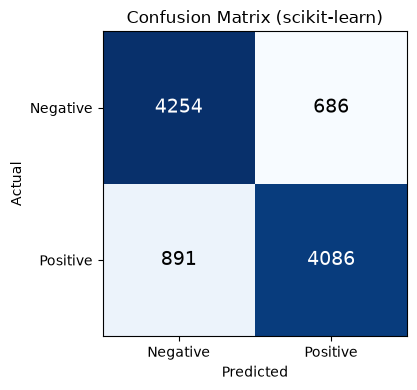

In [7]:
# Train and predict with scikit-learn

nb_sklearn = MultinomialNB(alpha=1.0)
nb_sklearn.fit(X_train, y_train)
y_pred_sklearn = nb_sklearn.predict(X_test)


# Metrics (positive class = 1)

sklearn_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_sklearn),
    "Precision": precision_score(y_test, y_pred_sklearn),
    "Recall": recall_score(y_test, y_pred_sklearn),
    "F1": f1_score(y_test, y_pred_sklearn),
}

print("scikit-learn metrics:")
for name, value in sklearn_metrics.items():
    print(f"  {name:10s}: {value:.4f}")


# Detailed report for both classes

print("\nClassification report:")
print(classification_report(y_test, y_pred_sklearn, target_names=["negative", "positive"], digits=4))


# Confusion matrix

cm_sklearn = confusion_matrix(y_test, y_pred_sklearn)
plot_confusion_matrix(cm_sklearn, "Confusion Matrix (scikit-learn)")

## 5. Comparison: From Scratch vs scikit-learn

| Check | What it shows |
|:---|:---|
| **Metrics table** | Accuracy, precision, recall and F1 side by side |
| **Prediction agreement** | Percentage of test reviews where both models give the same label |
| **Log-probability difference** | Largest absolute difference between the two models' log probabilities; a value near zero (around 1e-10 or smaller) confirms the implementation is mathematically equivalent |
| **Training and prediction time** | Speed of each implementation |
| **Confusion matrices** | Side by side |

,From scratch,scikit-learn,Difference
Accuracy,0.840980,0.840980,0.0
Precision,0.856245,0.856245,0.0
Recall,0.820976,0.820976,0.0
F1,0.838240,0.838240,0.0



Prediction agreement: 100.00%
Max |difference| in log priors:         1.4432899320127035e-15
Max |difference| in feature log probs:  0.0
Max |difference| in log posteriors:     2.2737367544323206e-13


,Fit time (s),Predict time (s)
From scratch,0.03723,0.00847
scikit-learn,0.01490,0.00765


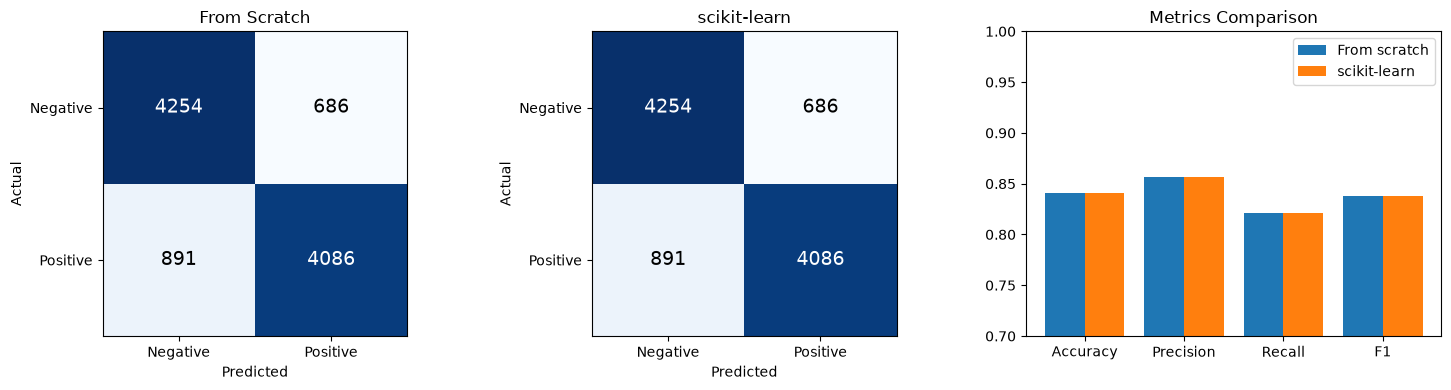

In [8]:
# Metrics table

comparison = pd.DataFrame({
    "From scratch": scratch_metrics,
    "scikit-learn": sklearn_metrics,
})
comparison["Difference"] = (comparison["From scratch"] - comparison["scikit-learn"]).abs()
display(comparison.round(6))


# Agreement between predictions

agreement = (y_pred_scratch == y_pred_sklearn).mean()
print(f"\nPrediction agreement: {agreement * 100:.2f}%")


# Verify the learned parameters and probabilities match

print("Max |difference| in log priors:        ",
      np.abs(nb_scratch.class_log_prior_ - nb_sklearn.class_log_prior_).max())
print("Max |difference| in feature log probs: ",
      np.abs(nb_scratch.feature_log_prob_ - nb_sklearn.feature_log_prob_).max())
print("Max |difference| in log posteriors:    ",
      np.abs(nb_scratch.predict_log_proba(X_test) - nb_sklearn.predict_log_proba(X_test)).max())


# Timing comparison

t0 = time.perf_counter()
MultinomialNaiveBayes(alpha=1.0).fit(X_train, y_train)
fit_scratch = time.perf_counter() - t0

t0 = time.perf_counter()
nb_scratch.predict(X_test)
pred_scratch = time.perf_counter() - t0

t0 = time.perf_counter()
MultinomialNB(alpha=1.0).fit(X_train, y_train)
fit_sklearn = time.perf_counter() - t0

t0 = time.perf_counter()
nb_sklearn.predict(X_test)
pred_sklearn = time.perf_counter() - t0

timing = pd.DataFrame({
    "Fit time (s)": [fit_scratch, fit_sklearn],
    "Predict time (s)": [pred_scratch, pred_sklearn],
}, index=["From scratch", "scikit-learn"])
display(timing.round(5))


# Side-by-side confusion matrices and metric bar chart

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_confusion_matrix(cm_scratch, "From Scratch", axes[0])
plot_confusion_matrix(cm_sklearn, "scikit-learn", axes[1])

x = np.arange(len(comparison))
axes[2].bar(x - 0.2, comparison["From scratch"], width=0.4, label="From scratch")
axes[2].bar(x + 0.2, comparison["scikit-learn"], width=0.4, label="scikit-learn")
axes[2].set_xticks(x); axes[2].set_xticklabels(comparison.index)
axes[2].set_ylim(0.7, 1.0)
axes[2].set_title("Metrics Comparison")
axes[2].legend()

plt.tight_layout()
plt.show()

## 6. Conclusion

- A Multinomial Naive Bayes classifier was implemented from scratch with NumPy and applied to IMDB sentiment analysis, using a 10,000-word bag-of-words representation shared with scikit-learn.
- **Performance:** the from-scratch model reached **84.10% accuracy**, with precision **0.8562**, recall **0.8210** and F1 **0.8382** on the held-out test set.
- **Equivalence with scikit-learn:** `MultinomialNB` produced identical metrics, and the two models agreed on **100%** of predictions. The learned feature log probabilities were exactly equal, and the log priors and log posteriors differed by at most **1.4e-15** and **2.3e-13**, which is floating-point rounding. This confirms the implementation is correct.
- **Error pattern:** precision (0.856) is higher than recall (0.821), so the model makes more **false negatives** than false positives. It misses some positive reviews more often than it wrongly labels negative reviews as positive.
- **Speed:** the from-scratch version took **0.037 s** to fit versus **0.015 s** for scikit-learn, and **0.0085 s** versus **0.0077 s** to predict. Both are very fast, and scikit-learn's advantage is small in absolute terms. These timings come from a single run, so treat them as approximate.
- **Limitations:** the independence assumption ignores word order and negation (e.g. "not good"), and bag-of-words discards context, which caps accuracy. Sequence models and transformers (Tasks 8 and 9) should do better on the same data.